# Voiceprint Verification Model

**Goal:** decide whether a voice belongs to an approved team member saying an approved phrase, and whether it matches the person already recognised by the face model.

**Pipeline:** load audio → visualise → augment → extract features (`audio_features.csv`) → train + evaluate → handle unauthorized voices → simulate verification.

> Run this notebook from the `voice_verification/` folder. It uses the same functions as the command-line app (`voice_verification.py`), so the notebook and the app behave the same way.

## 1. Setup and data locations

The next cell imports the audio-processing and plotting libraries, then checks the input folders before analysis. The notebook expects `voice_verification/` to be the working directory because its scripts and output paths are relative to that folder. Confirm that the folder counts are plausible; the inventory and feature table below provide more detailed checks. If an import fails, install the missing dependency into the notebook's selected Python environment before continuing.

In [1]:
import os, glob, warnings
warnings.filterwarnings("ignore", message="Unknown solver options")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa, librosa.display
from IPython.display import Audio, display

from voice_verification import load_audio, augment, extract_features, verify_voice, SR

AUDIO_DIR  = os.path.join("data", "audio")
UNAUTH_DIR = os.path.join("data", "audio_unauthorized")
DEMO_DIR   = os.path.join("data", "demo_clips")

for d in (AUDIO_DIR, UNAUTH_DIR, DEMO_DIR):
    print(f"{d:32s} {len(glob.glob(os.path.join(d, '*.wav')))} wav files")

data\audio                       8 wav files
data\audio_unauthorized          4 wav files
data\demo_clips                  2 wav files


## 2. Recording inventory and quality checks

This section inventories the genuine team recordings, labels each clip by speaker and phrase from its filename, and reports recording duration and clip counts. Both required phrases should be represented for every team member. The raw sample count matters: augmentations are derived from these recordings and do not replace collecting more independent recordings. The unauthorized recordings are kept separate from genuine speaker data and are summarized in the feature-table section.

In [2]:
def parse_name(path):
    stem = os.path.splitext(os.path.basename(path))[0].lower()
    member = stem.split("_")[0]
    phrase = "yesapprove" if "approve" in stem else "confirm" if "confirm" in stem else "other"
    return member, phrase

inventory = pd.DataFrame(
    [(*parse_name(p), os.path.basename(p), round(librosa.get_duration(path=p), 2))
     for p in sorted(glob.glob(os.path.join(AUDIO_DIR, "*.wav")))],
    columns=["member", "phrase", "file", "duration_s"])
display(inventory)
display(inventory.groupby("member").size().rename("clips"))

C:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,member,phrase,file,duration_s
0,blessing,confirm,blessing_confirm_01.wav,3.17
1,blessing,yesapprove,blessing_yesapprove_01.wav,2.82
2,davy,confirm,davy_confirm_01.wav,2.86
3,davy,yesapprove,davy_yesapprove_01.wav,3.33
4,gabriella,confirm,gabriella_confirm_01.wav,2.55
5,gabriella,yesapprove,gabriella_yesapprove_01.wav,2.59
6,kagaba,confirm,kagaba_confirm_01.wav,3.64
7,kagaba,yesapprove,kagaba_yesapprove_01.wav,3.39


member
blessing     2
davy         2
gabriella    2
kagaba       2
Name: clips, dtype: int64

### Interpretation of the inventory

The inventory contains **8 genuine recordings**: two phrases for each of four members. Clip durations range from **2.55 to 3.64 seconds**. This meets the two-phrase demonstration requirement, but two independent recordings per member are not enough to represent normal variation in speaking style, distance, room, or microphone.

## 3. Waveforms and spectrograms

The following cell displays the trimmed waveform and a short-time Fourier spectrogram for each genuine recording, followed by an audio player. Use the waveform to inspect silence, clipping, and level consistency; use the spectrogram to compare speech timing and frequency patterns. Review the plots rather than assuming that a recording is clean just because it loads successfully.

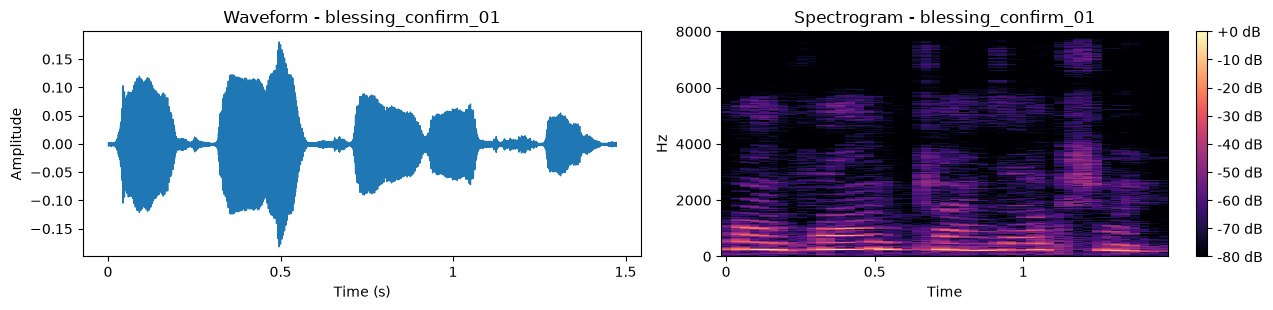

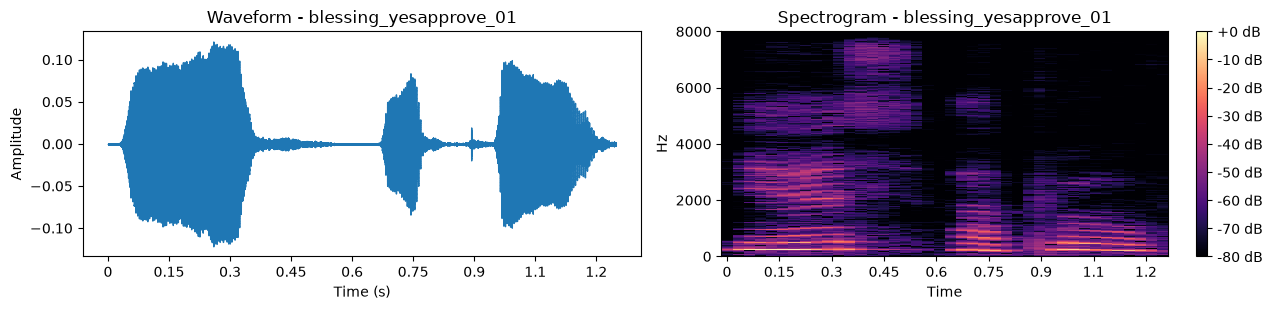

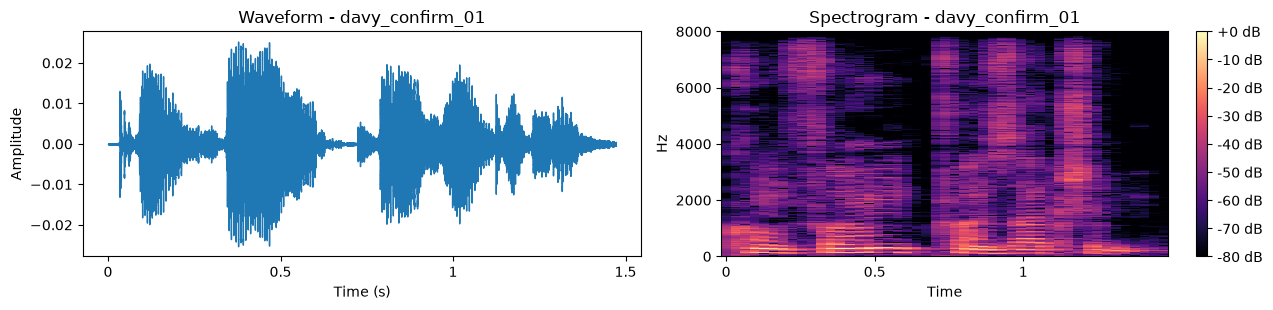

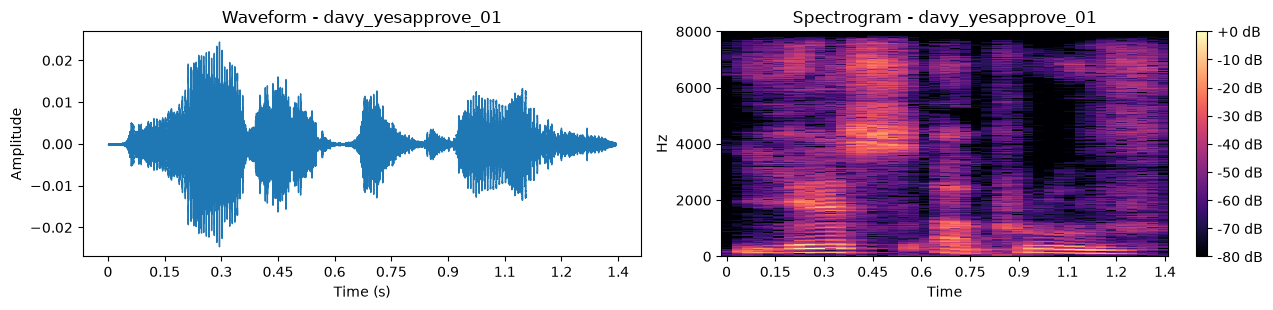

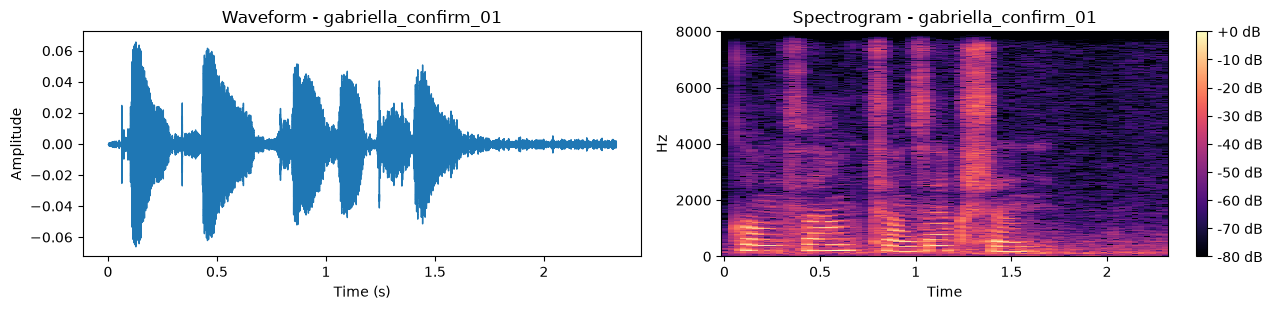

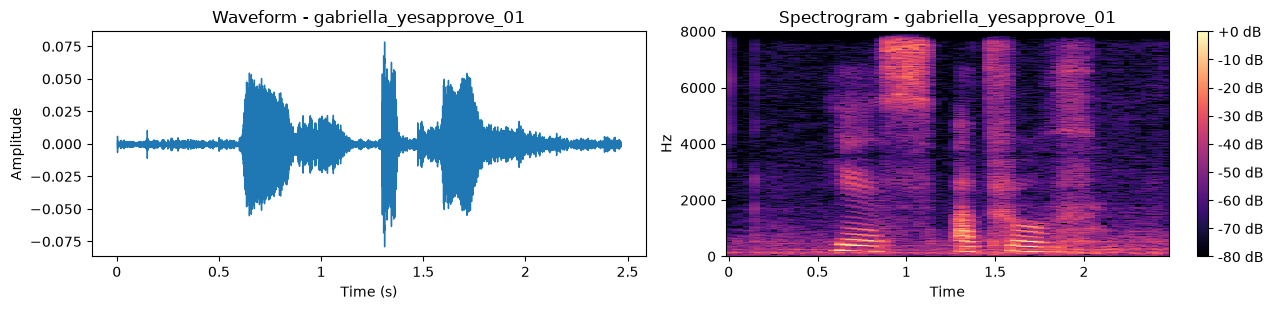

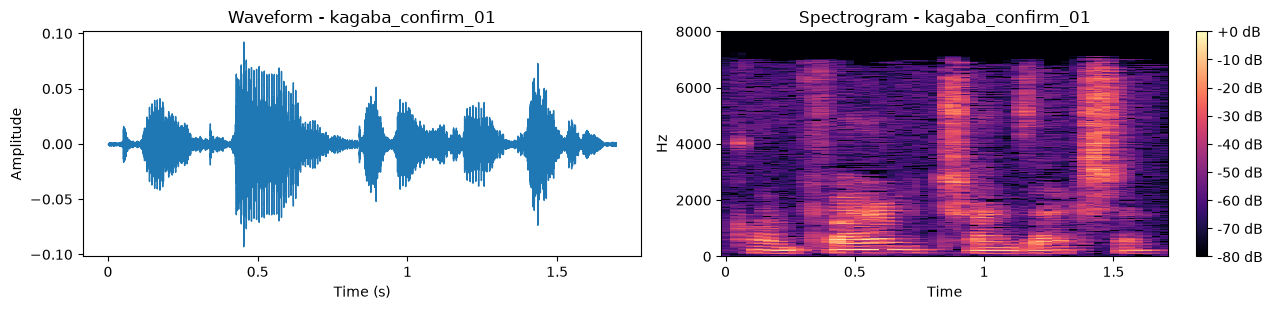

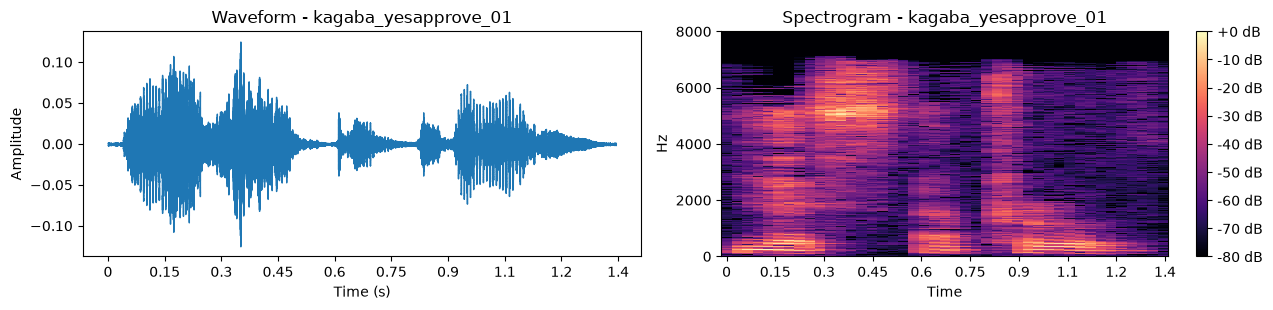

In [3]:
def plot_clip(y, title):
    fig, ax = plt.subplots(1, 2, figsize=(13, 3.2))
    librosa.display.waveshow(y, sr=SR, ax=ax[0])
    ax[0].set(title=f"Waveform - {title}", xlabel="Time (s)", ylabel="Amplitude")
    S = librosa.amplitude_to_db(np.abs(librosa.stft(y)), ref=np.max)
    img = librosa.display.specshow(S, sr=SR, x_axis="time", y_axis="hz", ax=ax[1])
    ax[1].set(title=f"Spectrogram - {title}")
    fig.colorbar(img, ax=ax[1], format="%+2.0f dB")
    plt.tight_layout(); plt.show()

for p in sorted(glob.glob(os.path.join(AUDIO_DIR, "*.wav"))):
    plot_clip(load_audio(p), os.path.splitext(os.path.basename(p))[0])
    display(Audio(p))

### Interpretation of the recording plots

The eight genuine clips last **2.55-3.64 seconds**, so both phrases are short enough to inspect individually. A numeric peak check found **no samples at or above 0.999** in these recordings, so there is no evidence of digital clipping. However, the peak amplitudes vary substantially: Davy's clips peak at about **0.025**, while Blessing's range from **0.122 to 0.181**. The plots and audio players should be checked for this level mismatch, background noise, and the timing of the spoken phrase.

A large level difference can become a shortcut for a small classifier rather than a reliable speaker cue. Re-record members at similar microphone distance and input level. The spectrogram can help compare speech frequency patterns, but visual differences alone do not prove speaker identity. These hand-engineered features and plots are educational checks, not a secure biometric or liveness test.

## 4. Audio augmentation

Each clip is expanded into seven versions: the original plus pitch shifts of +/-2 semitones, time stretches at 1.1x and 0.9x, and low/high Gaussian noise. The next cell visualizes and plays the versions of one sample. These transformations can improve tolerance to small recording changes, but they are synthetic variations of the same source clip and must stay in the same validation group as that source to avoid data leakage.

C:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\librosa\effects.py:448: FutureWarning: The `hop_length` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(
C:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\librosa\effects.py:448: FutureWarning: The `n_fft` parameter is deprecated as of 1.0 and will be removed in 1.1. It is unused in the current implementation.
  stft_stretch = core.phase_vocoder(


C:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\numba\np\ufunc\dufunc.py:303: RuntimeWarning: invalid value encountered in cast
  return super().__call__(*args, **kws)


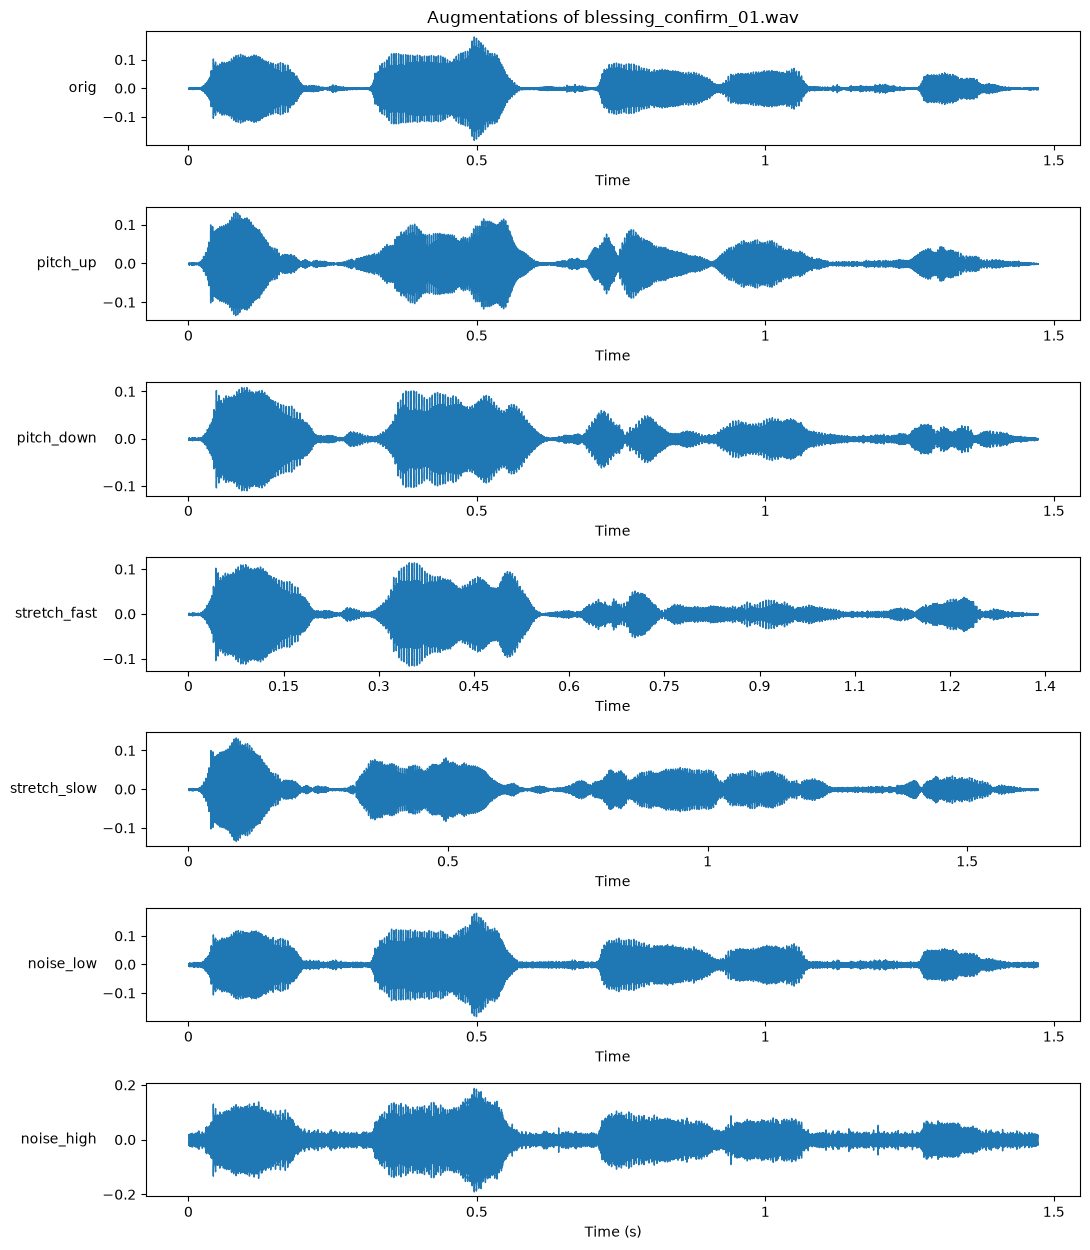

orig


pitch_up


pitch_down


stretch_fast


stretch_slow


noise_low


noise_high


In [4]:
sample = sorted(glob.glob(os.path.join(AUDIO_DIR, "*.wav")))[0]
y = load_audio(sample)
augs = augment(y)

fig, axes = plt.subplots(len(augs), 1, figsize=(11, 1.8 * len(augs)), sharex=False)
for ax, (name, sig) in zip(axes, augs.items()):
    librosa.display.waveshow(sig, sr=SR, ax=ax)
    ax.set_ylabel(name, rotation=0, ha="right", va="center")
axes[0].set_title(f"Augmentations of {os.path.basename(sample)}")
axes[-1].set_xlabel("Time (s)")
plt.tight_layout(); plt.show()

for name, sig in augs.items():
    print(name); display(Audio(sig, rate=SR))

### Interpretation of the augmentation preview

The preview applies six transformations to the first sorted genuine clip. Use the waveform and audio players to confirm that the phrase remains intelligible and the changes are modest. If a transformed clip becomes unintelligible or changes perceived speaker identity, reduce the transformation strength or omit it. These variants remain grouped with their source clip during validation and do not count as additional independent recordings.

## 5. Feature extraction and validation

`audio_features.csv` is created by `build_audio_features.py` from the recordings and their augmentations. Regenerate it with `python build_audio_features.py` after adding or replacing recordings. The next cells check its dimensions, missing values, label balance, and the distributions of selected original-recording features.

The 34 numeric features are the means and standard deviations of 13 MFCCs plus spectral roll-off, centroid, bandwidth, zero-crossing rate, RMS energy, and mean-square energy. The metadata columns identify speaker, phrase, source recording, and augmentation; `source_file` is used to keep related versions together during evaluation.

In [5]:
df = pd.read_csv("audio_features.csv")
META = ["member", "phrase", "source_file", "augmentation"]
cols = [c for c in df.columns if c not in META]
print("shape:", df.shape, "| feature columns:", len(cols), "| missing values:", int(df[cols].isna().sum().sum()))
display(df.head())
display(df.groupby("member").size().rename("rows per class"))

shape:

 (84, 36) | feature columns: 32 | missing values: 0


,member,phrase,source_file,augmentation,mfcc1_mean,mfcc1_std,mfcc2_mean,mfcc2_std,mfcc3_mean,mfcc3_std,...,mfcc12_mean,mfcc12_std,mfcc13_mean,mfcc13_std,spectral_rolloff,spectral_centroid,spectral_bandwidth,zcr,rms_energy,energy
0,blessing,confirm,blessing_confirm_01,orig,-420.317993,46.960655,108.681984,36.455753,7.441428,17.120888,...,-11.494939,7.743986,-2.340917,7.747578,1802.360372,1061.164303,1292.171856,0.067507,0.033616,0.001616
1,blessing,confirm,blessing_confirm_01,pitch_up,-438.557587,43.647964,106.697601,29.539492,2.547743,15.112432,...,3.024345,9.847264,-17.340170,7.619511,1858.045213,1074.071621,1304.799501,0.065669,0.025361,0.000926
2,blessing,confirm,blessing_confirm_01,pitch_down,-450.065613,41.740761,118.204071,29.239420,5.472946,14.930391,...,-25.986574,9.509166,-5.583918,9.560990,1610.704787,906.695525,1163.832613,0.049929,0.024198,0.000868
3,blessing,confirm,blessing_confirm_01,stretch_fast,-437.590118,38.584137,112.029587,29.999430,3.274331,14.229032,...,-12.013102,6.614336,-3.046243,8.287989,1829.427083,1043.948770,1312.963075,0.059535,0.023866,0.000863
4,blessing,confirm,blessing_confirm_01,stretch_slow,-446.981384,41.403393,106.153702,32.298355,4.447649,15.414147,...,-13.010263,6.205173,-2.512872,6.855196,1826.622596,1050.077331,1324.824741,0.057317,0.022272,0.000716


member
blessing     14
davy         14
gabriella    14
kagaba       14
unknown      28
Name: rows per class, dtype: int64

### Interpretation of the feature table

The current file has **84 rows, 36 columns, 32 numeric features, and no missing feature values**. It contains four known speakers with 14 rows each and an `unknown` class with 28 rows; those row counts include augmentations. There are only **2 original clips per known speaker and 4 original unknown clips**, so the larger augmented table should not be mistaken for a large independent dataset. Regenerate the CSV whenever source recordings change.

### Compare selected features across speakers

The boxplots below use only the original recordings, not augmented copies. Comparing distributions helps identify potentially useful speaker cues and also reveals overlap. Because each known speaker has only two originals, these plots are descriptive and cannot establish reliable separation.


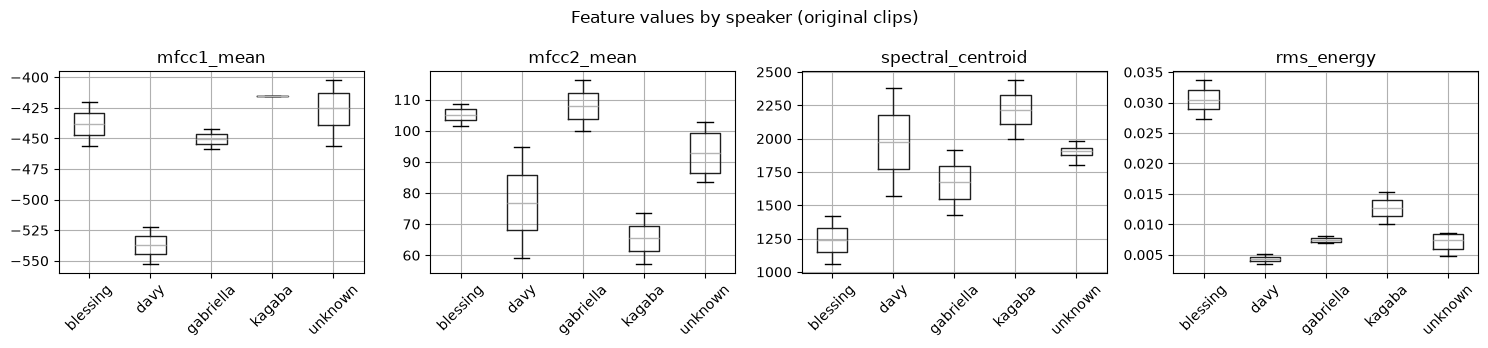

In [6]:
orig = df[df.augmentation == "orig"]
show = ["mfcc1_mean", "mfcc2_mean", "spectral_centroid", "rms_energy"]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.5))
for ax, c in zip(axes, show):
    orig.boxplot(column=c, by="member", ax=ax, rot=45)
    ax.set_title(c); ax.set_xlabel("")
plt.suptitle("Feature values by speaker (original clips)"); plt.tight_layout(); plt.show()

### Interpretation of feature distributions

The selected feature distributions show both potentially useful differences and a data-quality concern. For example, original-clip RMS energy ranges from **0.0274-0.0336 for Blessing** but only **0.0035-0.0051 for Davy**. Some plotted MFCC and spectral ranges also differ by speaker, but there are only two original observations per known person, and the unknown ranges overlap known speakers. The model may exploit recording level or phrase/microphone differences rather than stable voice identity. Collect more recordings at consistent levels before drawing conclusions from these boxplots.

## 6. Train and evaluate candidate classifiers

This section compares Random Forest with scaled Logistic Regression using leave-one-source-recording-out evaluation. All seven versions of a source recording stay together, and only the original clip is scored. This avoids the misleading results a random row split could produce when a near-duplicate augmentation appears in training and testing.

Accuracy and macro F1 summarize class predictions; log loss evaluates the predicted probabilities (lower is better). With only two original recordings per known speaker, each held-out clip has substantial influence on the scores. Treat them as a preliminary classroom comparison, not production performance.

In [7]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import (accuracy_score, f1_score, log_loss,
                             classification_report, ConfusionMatrixDisplay)

X, y_lab, groups = df[cols], df["member"], df["source_file"]
classes = np.array(sorted(y_lab.unique()))

models = {
    "RandomForest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42),
    "LogisticRegression": make_pipeline(StandardScaler(),
                                        LogisticRegression(max_iter=3000, C=1.0, class_weight="balanced")),
}

def leave_one_clip_out(model):
    true, pred, probas = [], [], []
    for tr, te in LeaveOneGroupOut().split(X, y_lab, groups):
        te = [i for i in te if df.augmentation.iloc[i] == "orig"]
        if not te:
            continue
        model.fit(X.iloc[tr], y_lab.iloc[tr])
        p = model.predict_proba(X.iloc[te])
        full = np.zeros((len(te), len(classes)))
        for j, c in enumerate(model.classes_):
            full[:, list(classes).index(c)] = p[:, j]
        true += list(y_lab.iloc[te]); pred += list(classes[full.argmax(1)]); probas.append(full)
    return true, pred, np.vstack(probas)

results, cv = {}, {}
for name, m in models.items():
    true, pred, probas = leave_one_clip_out(m)
    pr = np.clip(probas, 1e-6, 1); pr = pr / pr.sum(axis=1, keepdims=True)
    results[name] = dict(accuracy=accuracy_score(true, pred),
                         f1_macro=f1_score(true, pred, average="macro"),
                         log_loss=log_loss(true, pr, labels=classes))
    cv[name] = (true, pred)

res = pd.DataFrame(results).T.round(3)
display(res)
print(f"{len(true)} held-out clips - one clip changes accuracy by about {100/len(true):.0f}%")

,accuracy,f1_macro,log_loss
RandomForest,0.583,0.576,0.987
LogisticRegression,0.917,0.931,0.489


12 held-out clips - one clip changes accuracy by about 8%


### Interpretation of cross-validation scores

On this **12-clip** leave-one-recording-out evaluation, Logistic Regression scored **0.917 accuracy, 0.931 macro F1, and 0.489 log loss**; Random Forest scored **0.583, 0.576, and 0.987**, respectively. Logistic Regression is the better candidate on these data. Each known speaker contributes only two held-out clips and `unknown` contributes four, so one error changes accuracy by about **8 percentage points**. The scores are exploratory and model selection on this same small cross-validation set can make the selected result optimistic.

Best model: LogisticRegression
              precision    recall  f1-score   support

    blessing       1.00      1.00      1.00         2
        davy       1.00      1.00      1.00         2
   gabriella       0.67      1.00      0.80         2
      kagaba       1.00      1.00      1.00         2
     unknown       1.00      0.75      0.86         4

    accuracy                           0.92        12
   macro avg       0.93      0.95      0.93        12
weighted avg       0.94      0.92      0.92        12



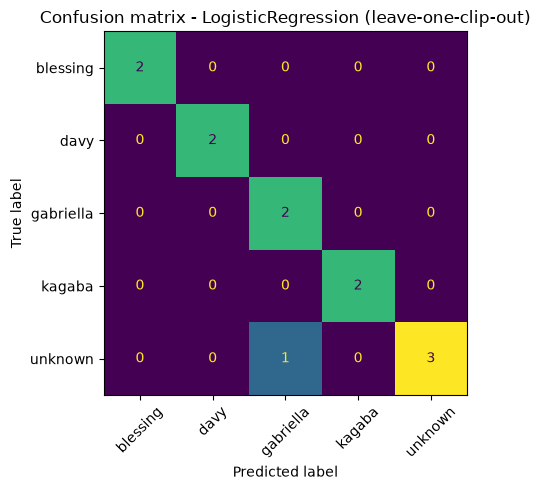

In [8]:
best = res.sort_values(["f1_macro", "log_loss"], ascending=[False, True]).index[0]
print("Best model:", best)
true, pred = cv[best]
print(classification_report(true, pred, zero_division=0))

fig, ax = plt.subplots(figsize=(5.5, 5))
ConfusionMatrixDisplay.from_predictions(true, pred, labels=classes, ax=ax, colorbar=False, xticks_rotation=45)
ax.set_title(f"Confusion matrix - {best} (leave-one-clip-out)")
plt.tight_layout(); plt.show()

### Interpretation of class-level errors

The Logistic Regression confusion matrix shows that the known-member clips were all classified correctly in this small split, but **one of four unknown clips (`kellia_yes_approve_01`) was classified as `gabriella`**. Thus, unknown recall is **0.75** and the model has a false-accept example even though its overall accuracy is 0.92. This is the most important error for the authentication use case. Keep this clip in the report as evidence that the current classifier and threshold are not security-grade.

### Results and discussion

The observed results favor Logistic Regression over Random Forest, but the **single unknown-to-Gabriella error** shows why accuracy alone is not enough for this task. The unknown class has only four independent recordings, so its recall and the selected model are highly sensitive to individual clips. These estimates do not establish how the verifier will perform on new people, rooms, microphones, or recording sessions. Use the false-accept case and the tiny sample size in the report, and evaluate again on fresh recordings that were never used in feature generation or model selection.

## 7. Fit the selected model and test authorization decisions

The following cell selects the better cross-validation candidate, fits it on all available feature rows, and saves the model bundle used by `verify_voice()`. It then checks genuine clips and the separate `data/demo_clips/` set. Genuine clips shown here were included in fitting, so acceptance is a functional smoke test rather than an independent evaluation. Demo clips are more informative only if they truly were not used to create `audio_features.csv`.

An authorization decision requires all three checks: the top class is not `unknown`, confidence meets the configured 0.5 threshold, and the predicted speaker matches the face-recognized `expected_user`. A fixed confidence threshold has not been calibrated for security, and this classifier cannot detect replay attacks or prove that the claimed phrase was spoken.

In [9]:
import joblib
final = models[best].fit(X, y_lab)
joblib.dump(dict(model=final, feature_cols=cols, threshold=0.5, classes=list(final.classes_)),
            "voice_model.joblib")

claimed = "blessing"   # pretend the face model recognised this user

print("--- Genuine clips ---")
for p in sorted(glob.glob(os.path.join(AUDIO_DIR, f"{claimed}_*.wav"))):
    r = verify_voice(p, claimed); print(f"{os.path.basename(p):32s}", r)

print("\n--- Unauthorized clips (speakers never seen in training) ---")
rejected = 0
demo = sorted(glob.glob(os.path.join(DEMO_DIR, "*.wav")))
for p in demo:
    r = verify_voice(p, claimed); rejected += (not r["authorized"])
    print(f"{os.path.basename(p):32s}", r)
print(f"\nOutsiders rejected: {rejected}/{len(demo)}")

--- Genuine clips ---


blessing_confirm_01.wav          {'authorized': True, 'predicted_user': 'blessing', 'confidence': 0.999486537371829, 'reason': 'voice verified'}
blessing_yesapprove_01.wav       {'authorized': True, 'predicted_user': 'blessing', 'confidence': 0.9906152386952184, 'reason': 'voice verified'}

--- Unauthorized clips (speakers never seen in training) ---


keke_confirm_01.wav              {'authorized': False, 'predicted_user': None, 'confidence': 0.488104361517136, 'reason': 'voice not recognised (confidence 0.49 < 0.50)'}
keke_yes_approve_01.wav          {'authorized': False, 'predicted_user': None, 'confidence': 0.901759989199971, 'reason': 'voice classified as an unauthorized speaker'}

Outsiders rejected: 2/2


### Interpretation

Both genuine Blessing clips were accepted, with confidence about **0.991-0.999**; these clips were included in fitting, so this is only a functional smoke test. Both `data/demo_clips/` outsiders were rejected (**2/2**), but for different reasons: `keke_confirm_01.wav` was just below the 0.5 threshold (**0.488**), while `keke_yes_approve_01.wav` was classified as `unknown` despite a top confidence of about **0.902**. The leave-one-recording-out test separately produced a false accept for an unknown clip, so this small demo does not show reliable stranger rejection. Confirm that demo files remain absent from `audio_features.csv` whenever you regenerate the features.

### Identity consistency check

This test passes a genuine team recording while claiming that the face step recognized a different member (`blessing`). A correctly wired multimodal gate should reject the request because the voice identity and face identity do not match, even if the voice is otherwise recognized with high confidence. This checks decision logic only; it is not an independent estimate of voice-model accuracy.

In [10]:
other = sorted(glob.glob(os.path.join(AUDIO_DIR, "davy_*.wav")))[0]
print(verify_voice(other, expected_user="blessing"))

{'authorized': False, 'predicted_user': 'davy', 'confidence': 0.9842803454802749, 'reason': "voice belongs to 'davy', not the face-verified user 'blessing'"}


### Identity-check interpretation

The test identified the supplied recording as `davy` with about **0.984 confidence**, but returned `authorized=False` because the expected face-verified user was `blessing`. This confirms that the identity-consistency gate rejects a known speaker when the face and voice identities disagree. It is a decision-logic check, not an independent accuracy measurement.

## 8. Limitations and next steps

1. **Collect more independent recordings:** there are currently two original clips per known member and four `unknown` clips. Record at least 3-5 or more varied takes per phrase and speaker, in more than one session, at similar microphone levels. Keep an untouched test set.
2. **Evaluate on genuinely new speakers and sessions:** the genuine demo clips in this notebook were used to fit the final model. Keep fresh recordings completely out of feature generation and training, and add more representative unauthorized speakers.
3. **Address the false accept before presenting security claims:** one held-out unknown clip was classified as Gabriella. Tune any reject threshold only on validation data, and report false acceptance and false rejection alongside accuracy, macro F1, and log loss. The 0.5 threshold is a demonstration setting, not a security guarantee.
4. **Phrase validation is not implemented:** this model classifies the speaker; it does not confirm that the user said `Yes, approve` or `Confirm transaction`. Add a separate phrase/keyword check if the assignment requires spoken confirmation.
5. **Replay/liveness is not implemented:** an audio recording of an approved speaker may pass. Do not describe this classroom model as secure authentication.
6. **Consider pretrained speaker embeddings** after collecting enough data; compare them using the same recording-level split and a genuinely independent test set.
